# 04 Exploration

Look at the data before modelling it. Every quoted number and chart comes from
[`analysis/report_stats.py`](../../analysis/report_stats.py), the generator of the report's tables
and figures, so this notebook and the report cannot disagree.

In [1]:
import os
import sys
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline").is_dir()))
sys.path.insert(0, "analysis")

import geopandas as gpd
import pandas as pd
from IPython.display import Markdown

import report_stats as rs

pd.set_option("display.max_colwidth", None)
areas = gpd.read_parquet(rs.SOURCE)
known = areas[areas["hours"].notna()]

## 1. A first look

In [2]:
print(f"{len(areas):,} areas, {areas.shape[1]} columns, coordinates in {areas.crs.name}")
areas[["id", "luokka", "tyyppi", "voimassaolo", "kesto", "rule_type", "hours", "duration_min", "status", "district"]].head()

8,754 areas, 22 columns, coordinates in EUREF-FIN / GK25FIN


,id,luokka,tyyppi,voimassaolo,kesto,rule_type,hours,duration_min,status,district
0,8001,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,KAMPINMALMI
1,8002,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,KAMPINMALMI
2,8003,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,TAKA-TÖÖLÖ
3,8004,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,ALPPIHARJU
4,8005,6.0,NaN,9-21,NaN,paid,"{""mon_fri"": [9, 21]}",NaN,official,ALPPIHARJU


Finnish columns are the raw register ([02](02_data_collection.ipynb), §2), English ones stage 3's
parse. `NaN` is a field the register leaves empty. Coordinates are metric, so `.area` is in m².

## 2. The typical area

The mode of each category and the median of each number, as in the course's "average survivor":

In [3]:
Markdown(rs.summary_statistics(areas))

### Summary statistics: mode or median of each variable

| Variable            | Typical value             | Share of stated   |   Distinct |   Missing |
|:--------------------|:--------------------------|:------------------|-----------:|----------:|
| Rule type           | paid                      | 50.8%             |          6 |         0 |
| Status              | official                  | 86.1%             |          3 |         0 |
| Space type          | No parking                | 47.2%             |         20 |      6886 |
| District            | KAMPINMALMI               | 16.8%             |         30 |         0 |
| Hours               | mon_fri 9-21, sat 9-18    | 32.9%             |         51 |      2931 |
| Season              | 1.4.-31.10.               | 82.6%             |          4 |      8731 |
| Time limit, minutes | 240 (middle half 240-240) |                   |            |      5951 |
| Area, m²            | 46 (middle half 25-84)    |                   |            |         0 |


The typical area is paid, Monday to Friday 9-21 and Saturday 9-18, four hours where a limit is
stated, 46 m², in Kampinmalmi. That hours pattern covers 32.9% of areas with hours: the dummy
baseline for stage 5. Most of the 2,931 areas without hours are bans and reserved bays, which
need none; the real gap is the `missing_hours` column:

In [4]:
no_hours = areas[areas["hours"].isna()]
pd.crosstab(no_hours["rule_type"], no_hours["status"])

status,missing_hours,official,uncertain
rule_type,,,
always_banned,0,860,17
banned_hours,36,0,8
free_limited,381,0,1
paid,561,0,6
reserved,0,975,25
unknown,0,0,61


## 3. What the city publishes

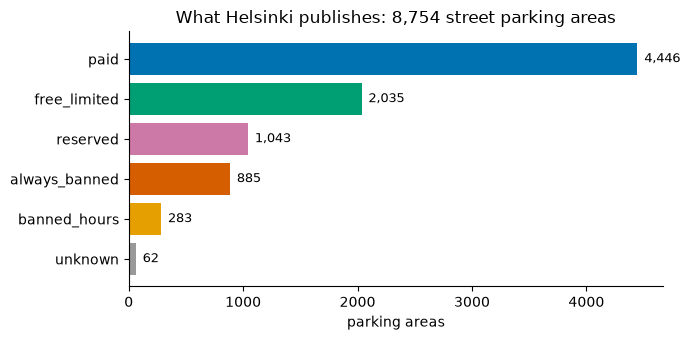

In [5]:
rs.plot_rule_types(areas);

Three quarters of street parking allows parking in some form. The rest, reserved and banned, is
where fines happen. Reserved bays look ordinary; they are for:

In [6]:
Markdown(rs.reserved_for(areas))

### Reserved areas by space type

| Reserved for          |   Areas |
|:----------------------|--------:|
| Electric scooter      |     312 |
| Electric car          |     187 |
| Taxi                  |     122 |
| Loading zone          |     100 |
| Accessible parking    |      88 |
| Tourist coach         |      63 |
| not stated            |      60 |
| Diplomatic vehicle    |      59 |
| Motorcycle            |      17 |
| Bicycle               |      14 |
| Taxi, charging        |       8 |
| Car or van            |       3 |
| Official vehicle      |       3 |
| Police                |       2 |
| City Executive Office |       1 |
| Mobile library        |       1 |
| Parklet               |       1 |
| Finnish Government    |       1 |
| Lorry                 |       1 |


## 4. Where the register is

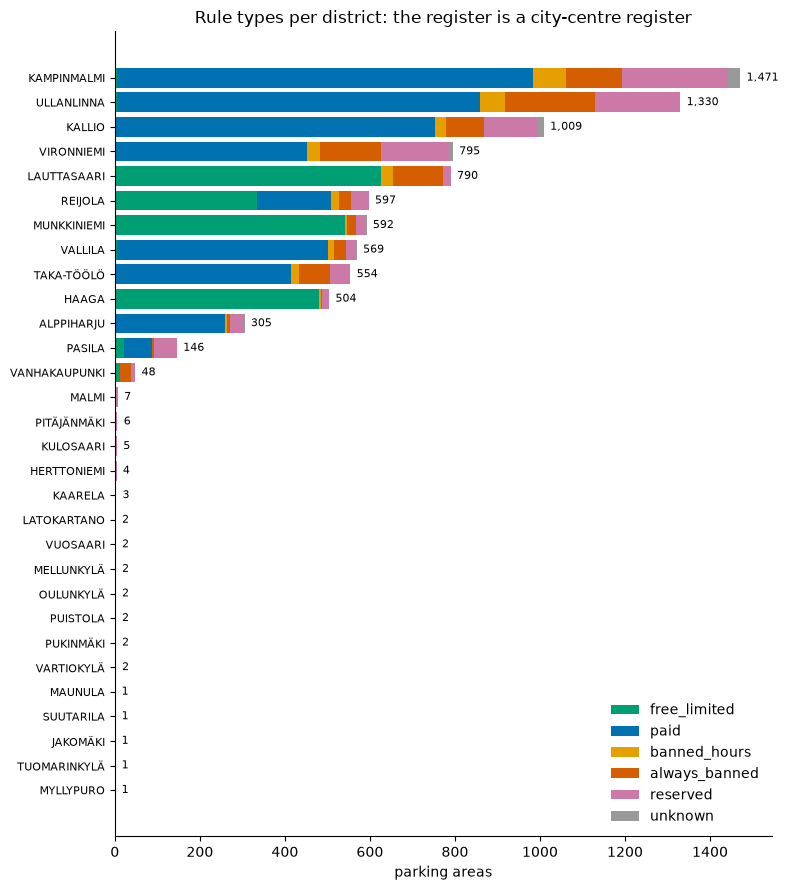

In [7]:
rs.plot_rule_type_by_district(areas);

A city-centre register: three central districts hold over 3,800 areas, while 17 of the 30 hold
fewer than ten. That most likely means no regulation there rather than no data, but the app
cannot tell a driver which. Rule types also cluster by district: the centre is paid, while
Lauttasaari, Munkkiniemi and Haaga are disc parking. So holding out a district in validation also
holds out a rule regime.

## 5. Time limits against rule type

In [8]:
Markdown(rs.duration_by_rule_type(areas))

### Time limit against rule type

| Time limit       |   always_banned |   banned_hours |   free_limited |   paid |   reserved |   unknown |
|:-----------------|----------------:|---------------:|---------------:|-------:|-----------:|----------:|
| none stated      |             883 |            281 |            372 |   3372 |        982 |        61 |
| no limit, stated |               0 |              0 |              0 |      0 |          7 |         0 |
| 15 min           |               0 |              0 |              5 |      0 |          5 |         0 |
| 30 min           |               0 |              0 |             16 |      3 |         17 |         0 |
| 1 h              |               0 |              1 |             27 |    457 |         13 |         0 |
| 2 h              |               0 |              1 |             20 |     84 |          6 |         0 |
| 4 h              |               2 |              0 |           1582 |    524 |          1 |         1 |
| 6 h              |               0 |              0 |              0 |      0 |          1 |         0 |
| 12 h             |               0 |              0 |              0 |      0 |          5 |         0 |
| 24 h             |               0 |              0 |             13 |      6 |          6 |         0 |


Mostly as expected, but the crosstab also finds what no single-column check would: bans with a
time limit,

In [9]:
odd = areas["duration_min"].notna() & areas["rule_type"].isin(["always_banned", "banned_hours", "unknown"])
areas.loc[odd, ["id", "rule_type", "luokka", "tyyppi", "voimassaolo", "kesto", "status"]]

,id,rule_type,luokka,tyyppi,voimassaolo,kesto,status
348,8354,always_banned,NaN,Pysäköintikielto,8-20,4 h,official
426,8434,always_banned,NaN,Pysäköintikielto,,4,official
774,8822,banned_hours,9.0,,"11-16, (11-16), 11-16",2 h,official
1585,9646,banned_hours,9.0,,9-17,60 min,official
8671,16971,unknown,NaN,8,6-24,4 h,uncertain


and a disc-parking area with no limit at all, once answered *free until 20:00*. Preprocessing now
marks it uncertain (03, §4):

In [10]:
silent = areas["rule_type"].eq("free_limited") & areas["duration_min"].isna() & areas["status"].ne("missing_hours")
areas.loc[silent, ["id", "luokka", "class_name_en", "voimassaolo", "kesto", "status"]]

,id,luokka,class_name_en,voimassaolo,kesto,status
8104,16390,8.0,Free short-term parking without a permit; use a parking disc,8-20,,uncertain


Register errors, raised on the board.

## 6. Polygon sizes

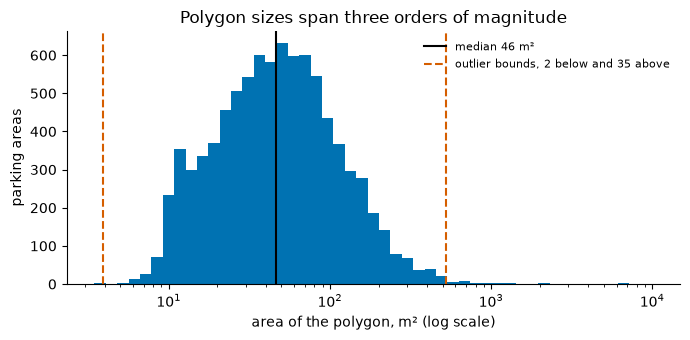

In [11]:
rs.plot_area_sizes(areas);

Outliers by the interquartile rule on the logarithm of the area, since on the raw scale only large
polygons could ever be outliers:

In [12]:
Markdown(rs.area_outliers(areas))

### Area sizes and outliers

| Measure               | Value         |
|:----------------------|:--------------|
| Median area           | 46 m²         |
| Smallest              | 3.5 m²        |
| Largest               | 9,977 m²      |
| Outlier bounds        | 3.9 to 527 m² |
| Below the lower bound | 2             |
| Above the upper bound | 35            |

### The smallest outliers and the five largest areas

|    Id | Rule type     | Space type   | District    |   Area, m² |
|------:|:--------------|:-------------|:------------|-----------:|
| 16661 | always_banned | No parking   | LAUTTASAARI |        3.5 |
| 16673 | always_banned | No parking   | LAUTTASAARI |        3.9 |
| 16732 | always_banned | No parking   | TAKA-TÖÖLÖ  |     9977.4 |
| 16606 | always_banned | No parking   | KALLIO      |     7093.6 |
| 16585 | always_banned | No parking   | ULLANLINNA  |     6743.4 |
| 16607 | always_banned | No parking   | KALLIO      |     2549.7 |
| 17035 | always_banned | No parking   | KALLIO      |     2167.1 |

13 of the 35 large outliers overlap another area, 31 areas in all.


The largest are no-parking squares, not street sections. Where one lies over a street section, a
tap can select the square instead:

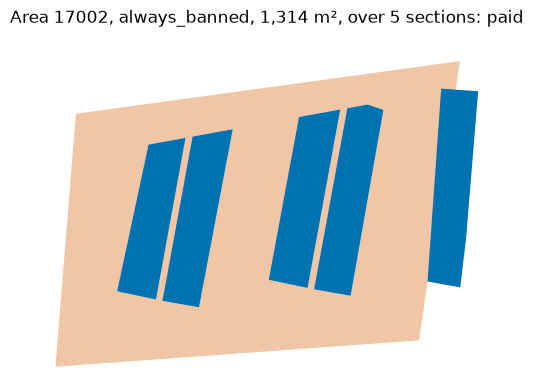

In [13]:
large, overlaps = rs.large_overlaps(areas)
zone_id = overlaps["id_right"].value_counts().index[0]
zone = areas[areas["id"] == zone_id]
under = areas[areas["id"].isin(overlaps.loc[overlaps["id_right"] == zone_id, "id_left"])]

ax = zone.plot(color=rs.RULE_COLOURS[zone["rule_type"].iloc[0]], alpha=0.35, figsize=(6, 6))
under.plot(ax=ax, color=[rs.RULE_COLOURS[r] for r in under["rule_type"]])
ax.set_title(f"Area {zone_id}, {zone['rule_type'].iloc[0]}, {zone.area.iloc[0]:,.0f} m², "
             f"over {len(under)} sections: {', '.join(sorted(under['rule_type'].unique()))}")
ax.set_axis_off();

The paid bays are most likely exceptions inside the square, so the smaller polygon is the one
that applies. The app selects whichever is drawn on top, so the export now writes the largest
areas first and every smaller one lands on top of them.

## 7. What the app can answer

In [14]:
Markdown(rs.coverage(areas))

### What the app can answer

| Status                          |   Areas |
|:--------------------------------|--------:|
| Complete rule published         |    7537 |
| Rule type known, hours missing  |     978 |
| Uncertain, with a stated reason |     239 |


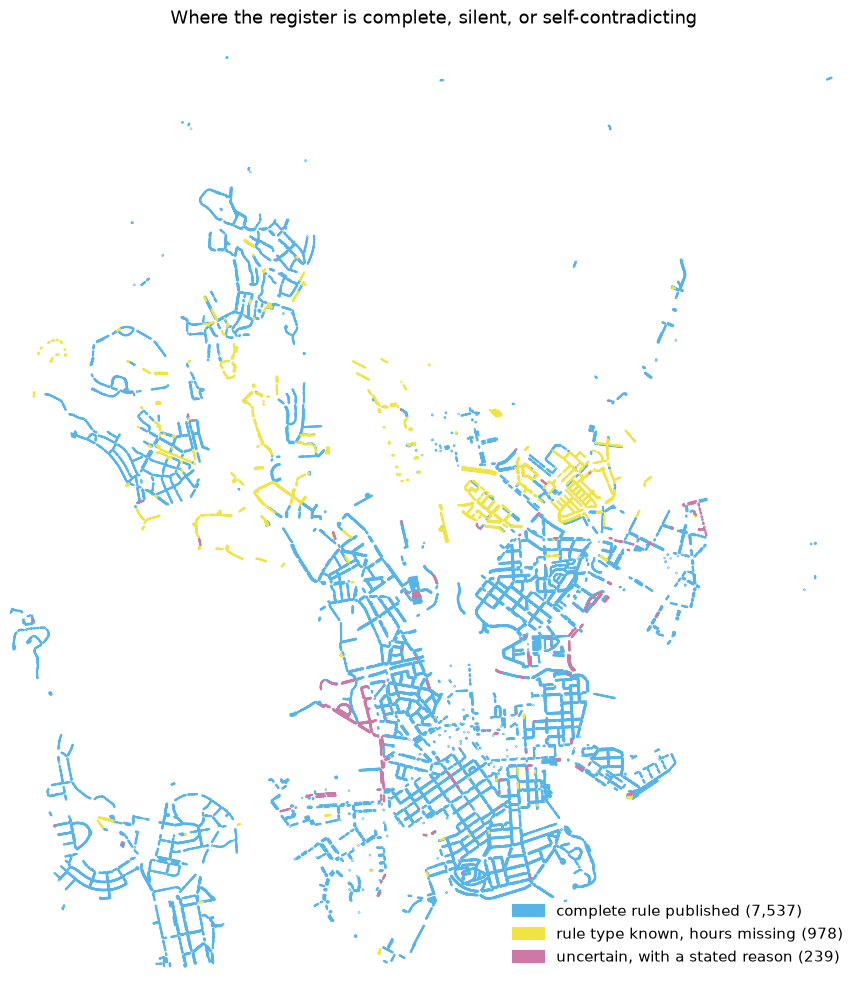

In [15]:
rs.plot_status_map(areas);

The gaps sit mostly outside the centre.

## 8. Can neighbours predict the missing hours?

Hide each area's hours, copy them from its nearest neighbour of the same class, and count how
often the copy is right:

In [16]:
paired = rs.nearest_pairs(known)
baseline = rs.baseline_accuracy(known)
by_dist = rs.accuracy_by_distance(paired)
Markdown(rs.neighbour_accuracy(paired, by_dist, baseline))

Copying the nearest same-class area is correct **97.5%** of the time, over 5,834 comparisons. Always guessing the most common pattern scores **32.9%**.

### Accuracy by distance

| Distance to nearest same-class area   |   Correct |   Areas |
|:--------------------------------------|----------:|--------:|
| 0-10 m                                |      99.5 |    4711 |
| 10-50 m                               |      95.5 |     706 |
| 50-200 m                              |      68.4 |     152 |
| over 200 m                            |      35.4 |      65 |


The same class matters: a paid section and the loading bay beside it need not share hours.

In [17]:
any_class = rs.nearest_pairs(known, same_class=False)
pd.Series({"same class": paired["match"].mean(), "any class": any_class["match"].mean()},
          name="hours copied correctly, %").mul(100).round(1)

same class    97.5
any class     88.9
Name: hours copied correctly, %, dtype: float64

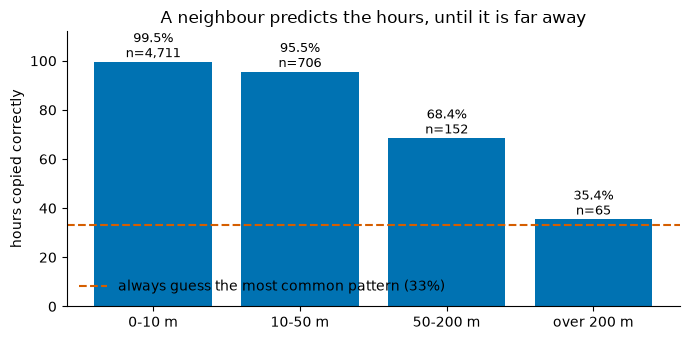

In [18]:
rs.plot_accuracy_by_distance(by_dist, baseline);

The catch: accuracy falls with distance, and the areas we need to predict are far from a known one.

In [19]:
Markdown(rs.prediction_gap(areas, known))

### Distance from a missing-hours area to the nearest area we can learn from

| Measure         | Value   |
|:----------------|:--------|
| Areas measured  | 978     |
| Median distance | 153 m   |
| Within 10 m     | 3.8%    |
| Within 50 m     | 17.7%   |
| Within 200 m    | 57.4%   |


At around 150 m, copying is right far less often than 97.5%. Expect a confident answer for some of
the 978 areas, and "unknown" for the rest.

## 9. Reflection

**Hands on:** to learning, the method (same-class nearest neighbours), the baseline (32.9%), an
honest expectation at the distances we will really face, and validation by district.

**The canvas planned** a map of missing and uncertain rules, the neighbour test, summary
statistics, a size histogram, rule type against district and time limit, and accuracy by
distance. All were produced.

**What worked:** the neighbour test chose the method and set its expectation (§8); the district
view changed the validation design (§4); the limit and size checks found problems for the app
(§5, §6).

**What did not, and why:** the status map was unreadable for weeks, because the chart was
generated and nobody looked at it at reading size. The summary table also misleads on its own:
"2,931 missing hours" needed the crosstab to read right.

**What changed:** exploration became a notebook over the report's generator, and the neighbour
test gained an any-class control.

**What we would do differently:** look at every figure at the size it will be read; explore the
fields we drop too, since spaces per area ([02](02_data_collection.ipynb), §2) would let us measure
coverage per parking space rather than per polygon.

**Future steps:** coverage and accuracy per parking space; measure the spatial clustering
formally, for example with Moran's I; fines per space for the street-level risk layer (S2).

**Experience and learning:** indexed spatial joins tested every area, not a sample, in seconds;
crosstabs did more than plots; the interquartile rule needed a log scale. Exploration chooses the
method and sets its limits, and an outlier can be a finding about the product, not the data.

> *Each of us: one line on what you took from this stage.*